# AF7 – Red Neuronal Prealimentada (RNP)

**Materia:** Inteligencia Artificial y Redes Neuronales – Grupo 004

**Nombres y matricula:**
* Angel Yahel Medina Herrera - 2102879
* Mario Alberto Tovanche Casillas - 2024432
* Jose Israel Bautista Rivera - 2127857
* Carlos Segura Cedillo - 2044463
* Humberto Jasso Valadez - 2070160

**Horario de clase:** Jueves N1

**Facultad:** FIME – UANL

## 1. Cargar librerías
Se usa **TensorFlow/Keras** para construir, entrenar y evaluar la red; **NumPy** para manejo de arreglos y **Matplotlib** para visualizar los dígitos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# Semilla para que los resultados sean reproducibles
tf.random.set_seed(42)
np.random.seed(42)

print("Versión de TensorFlow:", tf.__version__)

Versión de TensorFlow: 2.21.0


## 2. Cargar datos
`mnist.load_data()` regresa la división predeterminada: **60,000** imágenes de entrenamiento y **10,000** de prueba, cada una de 28×28 píxeles en escala de grises (0–255).

In [2]:
(train_data, train_labels), (test_data, test_labels) = mnist.load_data()

print("train_data:  ", train_data.shape, " train_labels:", train_labels.shape)
print("test_data:   ", test_data.shape,  " test_labels: ", test_labels.shape)
print("Rango de píxeles:", train_data.min(), "-", train_data.max())
print("Clases:", np.unique(train_labels))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
train_data:   (60000, 28, 28)  train_labels: (60000,)
test_data:    (10000, 28, 28)  test_labels:  (10000,)
Rango de píxeles: 0 - 255
Clases: [0 1 2 3 4 5 6 7 8 9]


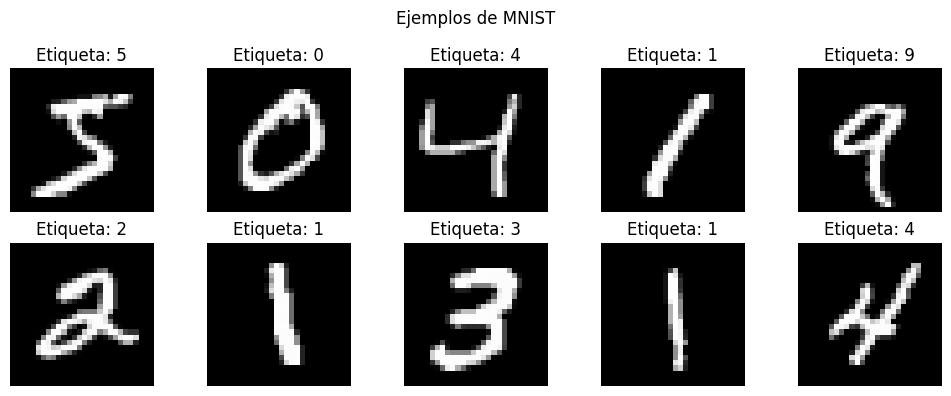

In [3]:
# Vista rápida de algunos ejemplos del conjunto de entrenamiento
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_data[i], cmap="gray")
    ax.set_title(f"Etiqueta: {train_labels[i]}")
    ax.axis("off")
plt.suptitle("Ejemplos de MNIST")
plt.tight_layout()
plt.show()

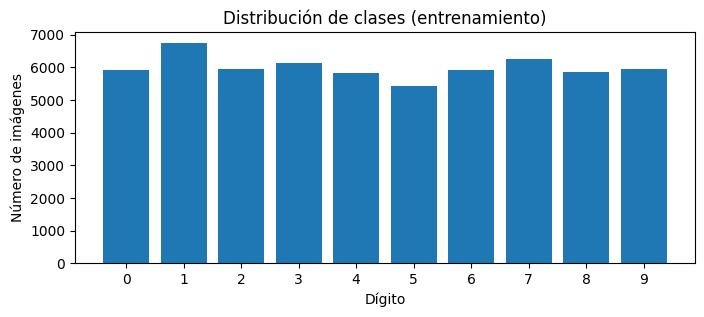

In [4]:
# Distribución de clases en entrenamiento
clases, conteos = np.unique(train_labels, return_counts=True)
plt.figure(figsize=(8, 3))
plt.bar(clases, conteos)
plt.xticks(clases)
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.title("Distribución de clases (entrenamiento)")
plt.show()

## 3. Preprocesamiento de datos
1. **Normalización:** se divide entre 255 para dejar los píxeles en el rango [0, 1]; esto estabiliza y acelera el entrenamiento.
2. **Tipo de dato:** se convierte a `float32`.
3. **Etiquetas:** se dejan como enteros (0–9), por eso se usa la pérdida `sparse_categorical_crossentropy` (no hace falta one-hot).
4. El aplanado de 28×28 → 784 se hace dentro del modelo con una capa `Flatten`.

In [5]:
train_data = train_data.astype("float32") / 255.0
test_data  = test_data.astype("float32") / 255.0

print("Nuevo rango de píxeles:", train_data.min(), "-", train_data.max())
print("Tipo de dato:", train_data.dtype)

Nuevo rango de píxeles: 0.0 - 1.0
Tipo de dato: float32


## 4. Selección y entrenamiento del modelo

**Estructura propuesta (red prealimentada / feedforward):**

| Capa | Neuronas | Activación | Propósito |
|---|---|---|---|
| Entrada + `Flatten` | 784 | – | Convierte la imagen 28×28 en un vector |
| Oculta 1 (`Dense`) | 256 | ReLU | Aprende rasgos generales (trazos) |
| `Dropout` | – | 20 % | Reduce el sobreajuste |
| Oculta 2 (`Dense`) | 128 | ReLU | Combina rasgos en patrones más complejos |
| Salida (`Dense`) | 10 | **Softmax** | Probabilidad de cada dígito (0–9) |

- **Función de pérdida:** `sparse_categorical_crossentropy` (clasificación multiclase con etiquetas enteras).
- **Optimizador:** `Adam` (tasa de aprendizaje 0.001).
- **Métrica:** `accuracy` (exactitud).

In [6]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Entrenamiento con la función fit (10 % de los datos de entrenamiento se usa como validación)
history = model.fit(
    train_data, train_labels,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=2
)

Epoch 1/10
422/422 - 5s - 11ms/step - accuracy: 0.9051 - loss: 0.3251 - val_accuracy: 0.9678 - val_loss: 0.1171
Epoch 2/10
422/422 - 5s - 11ms/step - accuracy: 0.9590 - loss: 0.1354 - val_accuracy: 0.9735 - val_loss: 0.0892
Epoch 3/10
422/422 - 3s - 8ms/step - accuracy: 0.9707 - loss: 0.0948 - val_accuracy: 0.9745 - val_loss: 0.0811
Epoch 4/10
422/422 - 3s - 8ms/step - accuracy: 0.9769 - loss: 0.0750 - val_accuracy: 0.9780 - val_loss: 0.0765
Epoch 5/10
422/422 - 4s - 10ms/step - accuracy: 0.9812 - loss: 0.0595 - val_accuracy: 0.9802 - val_loss: 0.0721
Epoch 6/10
422/422 - 4s - 10ms/step - accuracy: 0.9837 - loss: 0.0512 - val_accuracy: 0.9800 - val_loss: 0.0720
Epoch 7/10
422/422 - 3s - 8ms/step - accuracy: 0.9855 - loss: 0.0431 - val_accuracy: 0.9808 - val_loss: 0.0718
Epoch 8/10
422/422 - 3s - 8ms/step - accuracy: 0.9874 - loss: 0.0380 - val_accuracy: 0.9805 - val_loss: 0.0699
Epoch 9/10
422/422 - 5s - 11ms/step - accuracy: 0.9887 - loss: 0.0337 - val_accuracy: 0.9805 - val_loss: 0.0

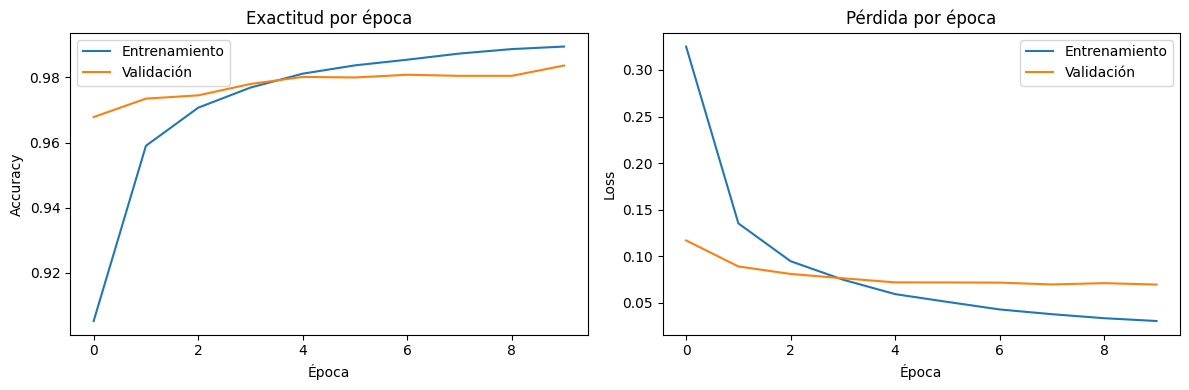

In [8]:
# Curvas de entrenamiento
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history["accuracy"], label="Entrenamiento")
ax1.plot(history.history["val_accuracy"], label="Validación")
ax1.set_title("Exactitud por época"); ax1.set_xlabel("Época"); ax1.set_ylabel("Accuracy"); ax1.legend()
ax2.plot(history.history["loss"], label="Entrenamiento")
ax2.plot(history.history["val_loss"], label="Validación")
ax2.set_title("Pérdida por época"); ax2.set_xlabel("Época"); ax2.set_ylabel("Loss"); ax2.legend()
plt.tight_layout()
plt.show()

## 5. Prueba del modelo
### 5.1 Evaluación con el conjunto de prueba
Se usa `evaluate` sobre `test_data`, imágenes que el modelo **nunca vio** durante el entrenamiento.

In [9]:
test_loss, test_accuracy = model.evaluate(test_data, test_labels, verbose=0)
print(f"Pérdida en prueba:   {test_loss:.4f}")
print(f"Exactitud en prueba: {test_accuracy:.4f}  ({test_accuracy*100:.2f} %)")

Pérdida en prueba:   0.0709
Exactitud en prueba: 0.9801  (98.01 %)


### 5.2 Cinco predicciones con el conjunto de prueba
Se eligen 5 imágenes al azar de `test_data` y se compara la **predicción** del modelo contra el **valor real**.

#  Índice   Predicción  Valor real  Confianza  Resultado
----------------------------------------------------------
1  6252     6           6           100.00 %   Correcta
2  4684     2           2           99.90 %    Correcta
3  1731     3           3           100.00 %   Correcta
4  4742     7           7           99.99 %    Correcta
5  4521     2           2           98.97 %    Correcta


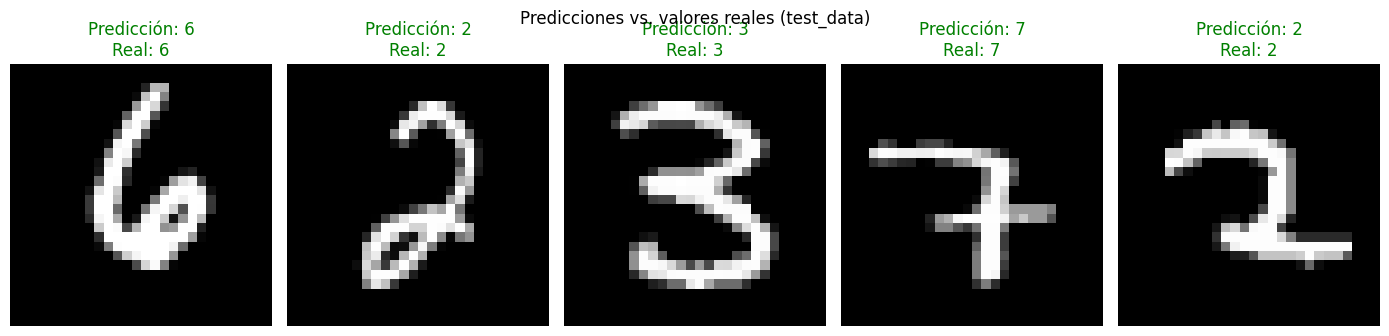

In [10]:
indices = np.random.choice(len(test_data), size=5, replace=False)
probabilidades = model.predict(test_data[indices], verbose=0)
predicciones = np.argmax(probabilidades, axis=1)

print(f"{'#':<3}{'Índice':<9}{'Predicción':<12}{'Valor real':<12}{'Confianza':<11}{'Resultado'}")
print("-" * 58)
for n, (idx, pred, prob) in enumerate(zip(indices, predicciones, probabilidades), start=1):
    real = test_labels[idx]
    resultado = "Correcta" if pred == real else "Incorrecta"
    print(f"{n:<3}{idx:<9}{pred:<12}{real:<12}{f'{prob[pred]*100:.2f} %':<11}{resultado}")

fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, idx, pred in zip(axes, indices, predicciones):
    real = test_labels[idx]
    ax.imshow(test_data[idx], cmap="gray")
    color = "green" if pred == real else "red"
    ax.set_title(f"Predicción: {pred}\nReal: {real}", color=color)
    ax.axis("off")
plt.suptitle("Predicciones vs. valores reales (test_data)")
plt.tight_layout()
plt.show()

## Conclusión
La red prealimentada con dos capas ocultas (256 y 128 neuronas, ReLU) y salida softmax clasifica correctamente la gran mayoría de los dígitos de prueba. La cercanía entre la exactitud de entrenamiento y la de validación indica que el `Dropout` ayudó a controlar el sobreajuste. Al tratar la imagen como un vector plano, la red no aprovecha la relación espacial entre píxeles; una red convolucional (CNN) sería el siguiente paso para superar el ~98 % de exactitud.